# E3 — Contact onset over approach velocity

`e3_approach.py`. Contact metrics per run, averaged over its approaches. The leader crosses the table at a
constant speed, holds 1 cm deep, and retracts to the pre-height (3 cm above). Expected: all methods converge at
low speed; under delay M1 drags before contact and feels it a round trip late; the model-based transients scale
with momentum (Λv for M5, mv for M4, none for M3).

The metric that works for every method is the **time to the hold force** (`hold_latency_ms`): from the leader's
crossing until the felt force is within ±20 % of its hold value for good. The force *onset* (a rise of 1 N)
suits M3–M5; M1 under delay drags more before contact than it feels in it, so its onset is meaningless
(negative). Contacts where osc_controller's contact force limiter fired are flagged (`contact_limited`).

In [1]:
# Runs to analyse: run directories, session files (exp/<exp>/sessions/*.txt, written by the script) or a
# folder of runs (a folder also holds retried and superseded runs). Default: the latest session file,
# which lists every condition once.
from common import latest_session

RUNS = [latest_session("e3")]
RECOMPUTE = True  # recompute the metrics from the data (runs analysed before hold_latency_ms existed lack it)
SWEEP_RTT = "850"  # the delay of the speed sweep
SWEEP_SPEED = 0.05  # the speed of the delay sweep [m/s]
# time series: (delay, approach speed [m/s], steady); one figure each, one column per method.
# steady: the M3–M5 steady-approach sweep (20 cm pre-height), else the main sweeps (3 cm)
TIMESERIES = [
    ("0", 0.05, False),
    ("850", 0.05, False),
    ("2600", 0.05, False),
    ("850", 0.20, False),
    ("850", 0.20, True),
]
CONTACT = 1  # which approach of the run (0, 1, 2): the second is clear of the start

In [2]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # before anything imports JAX: the GPU stays free for fr3_teleop's IK
import sys
from pathlib import Path

HERE = Path.cwd()  # experiments/rim-delays/exp
sys.path[:0] = [str(HERE), str(HERE.parent)]
import matplotlib.pyplot as plt  # noqa: I001
import numpy as np
import pandas as pd

import exp_metrics
import plots as P
from common import collect, load_table

%matplotlib inline
%load_ext autoreload
%autoreload 2  # pick up edits to exp_metrics / plots / common without a kernel restart
pd.set_option("display.precision", 3)

runs = collect(RUNS)
df = load_table(runs, exp_metrics.e3 if RECOMPUTE else None)
print(f"{len(df)} runs")

28 runs


In [3]:
df["T"] = df.rtt.map(P.delay_key)
df["steady"] = df.label.fillna("").str.endswith("steady")  # the M3–M5 steady-approach sweep
cols = [
    "run",
    "method",
    "T",
    "approach_speed",
    "contacts",
    "hold_latency_ms_mean",
    "felt_at_crossing_N_mean",
    "felt_settled_N_mean",
    "onset_latency_ms_mean",
    "overshoot_mean",
    "robot_peak_table_N_mean",
    "eF_z_mean_mean",
    "contact_limited_mean",
    "E_min_J",
]
df[[c for c in cols + ["steady"] if c in df]].sort_values(["steady", "T", "approach_speed", "method"])

,run,method,T,approach_speed,contacts,hold_latency_ms_mean,felt_at_crossing_N_mean,felt_settled_N_mean,onset_latency_ms_mean,overshoot_mean,robot_peak_table_N_mean,eF_z_mean_mean,contact_limited_mean,E_min_J,steady
18,20261026_160707_e3_proxy-fixed-mass_rtt0_v5cm,proxy-fixed-mass,0,0.05,3,87.995,-7.999e-01,10.000,-9.332,1.088,10.005,1.192e+00,0.0,-8.296e-01,False
17,20261026_160620_e3_proxy-god-object_rtt0_v5cm,proxy-god-object,0,0.05,3,89.000,0.000e+00,10.000,0.000,1.085,10.102,1.227e+00,0.0,-9.323e-01,False
19,20261026_160751_e3_proxy-rim_rtt0_v5cm,proxy-rim,0,0.05,3,88.002,-9.321e-01,10.000,-9.332,1.088,9.823,1.360e+00,0.0,-8.454e-01,False
16,20261026_155351_e3_zoh_rtt0_v5cm,zoh,0,0.05,3,115.998,5.140e+00,9.483,109.670,1.107,10.412,-9.553e-04,0.0,-0.000e+00,False
26,20261026_163156_e3_proxy-fixed-mass_rtt2600_v5cm,proxy-fixed-mass,2600,0.05,3,88.000,-7.923e-01,10.000,-9.332,1.088,10.070,1.012e+00,0.0,-8.052e-01,False
25,20261026_163044_e3_proxy-god-object_rtt2600_v5cm,proxy-god-object,2600,0.05,3,88.999,0.000e+00,10.000,0.000,1.085,10.145,9.895e-01,0.0,-9.174e-01,False
27,20261026_163320_e3_proxy-rim_rtt2600_v5cm,proxy-rim,2600,0.05,3,87.999,-9.061e-01,10.000,-9.333,1.088,9.756,1.494e+00,0.0,-8.336e-01,False
24,20261026_162912_e3_zoh_rtt2600_v5cm,zoh,2600,0.05,3,2719.000,2.941e+01,9.556,-9.334,4.140,10.513,1.631e+01,0.0,-0.000e+00,False
22,20261026_160922_e3_proxy-fixed-mass_rtt5g_v5cm,proxy-fixed-mass,5g,0.05,3,88.001,-7.981e-01,10.000,-9.665,1.088,10.041,1.246e+00,0.0,-8.337e-01,False
21,20261026_160839_e3_proxy-god-object_rtt5g_v5cm,proxy-god-object,5g,0.05,3,89.002,0.000e+00,10.000,0.000,1.085,10.051,1.261e+00,0.0,-9.479e-01,False


## Run checks

Every run should have ended normally, with the measured lag equal to the configured delay. `limit` is
osc_controller's contact force limiter: events during the run (`None`: not logged, runs before the logging).
At T ≥ 2 s the leader holds 4 s and rests 3 s (`LONG_DELAY` in the script) so the contact reaches the operator
during the hold.

In [4]:
from runs import load_run

loaded = {r: load_run(r) for r in df.dir}
df["stop_reason"] = [loaded[r]["meta"].get("stop_reason") for r in df.dir]
df["limit_events"] = [(loaded[r]["meta"].get("contact_limit") or {}).get("events") for r in df.dir]
df["hold_s"] = [loaded[r]["meta"]["script"]["hold_s"] for r in df.dir]
df["rest_s"] = [loaded[r]["meta"]["script"]["rest_s"] for r in df.dir]
df["clamp_N"] = [(loaded[r]["meta"].get("haptic_step") or {}).get("max_force_world") for r in df.dir]
df[["run", "method", "T", "approach_speed", "stop_reason", "limit_events", "hold_s", "rest_s", "clamp_N"]].sort_values(
    ["T", "approach_speed", "method"]
)

,run,method,T,approach_speed,stop_reason,limit_events,hold_s,rest_s,clamp_N
18,20261026_160707_e3_proxy-fixed-mass_rtt0_v5cm,proxy-fixed-mass,0,0.05,run ended,0,2.0,1.0,250.0
17,20261026_160620_e3_proxy-god-object_rtt0_v5cm,proxy-god-object,0,0.05,run ended,0,2.0,1.0,250.0
19,20261026_160751_e3_proxy-rim_rtt0_v5cm,proxy-rim,0,0.05,run ended,0,2.0,1.0,250.0
16,20261026_155351_e3_zoh_rtt0_v5cm,zoh,0,0.05,run ended,0,2.0,1.0,250.0
26,20261026_163156_e3_proxy-fixed-mass_rtt2600_v5cm,proxy-fixed-mass,2600,0.05,run ended,0,4.0,3.0,250.0
25,20261026_163044_e3_proxy-god-object_rtt2600_v5cm,proxy-god-object,2600,0.05,run ended,0,4.0,3.0,250.0
27,20261026_163320_e3_proxy-rim_rtt2600_v5cm,proxy-rim,2600,0.05,run ended,0,4.0,3.0,250.0
24,20261026_162912_e3_zoh_rtt2600_v5cm,zoh,2600,0.05,run ended,0,4.0,3.0,250.0
22,20261026_160922_e3_proxy-fixed-mass_rtt5g_v5cm,proxy-fixed-mass,5g,0.05,run ended,0,2.0,1.0,250.0
21,20261026_160839_e3_proxy-god-object_rtt5g_v5cm,proxy-god-object,5g,0.05,run ended,0,2.0,1.0,250.0


## Against the approach speed (at `SWEEP_RTT`)

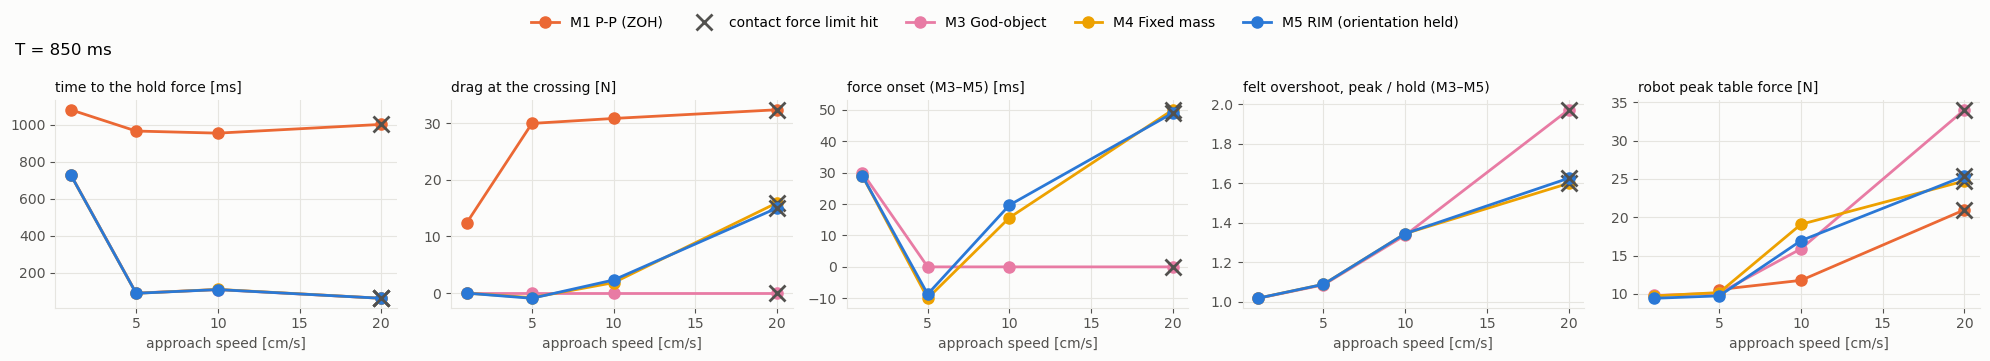

In [5]:
metrics = [
    ("hold_latency_ms_mean", "time to the hold force [ms]"),
    ("felt_at_crossing_N_mean", "drag at the crossing [N]"),
    ("onset_latency_ms_mean", "force onset (M3–M5) [ms]"),
    ("overshoot_mean", "felt overshoot, peak / hold (M3–M5)"),
    ("robot_peak_table_N_mean", "robot peak table force [N]"),
]

sub = df[(df["T"] == SWEEP_RTT) & ~df.steady]
fig, axes = plt.subplots(1, len(metrics), figsize=(4 * len(metrics), 3.3))
for ax, (y, title) in zip(axes, metrics):
    for m in P.methods_in(sub):
        s = sub[sub.method == m].groupby("approach_speed")[[y, "contact_limited_mean"]].mean()
        undefined = y in ("onset_latency_ms_mean", "overshoot_mean") and m == "zoh"  # M1: drag, not an onset
        y_ = s[y] * np.nan if undefined else s[y]
        ax.plot(
            100 * s.index, y_, "o-", lw=2, ms=8, color=P.color(m), label=P.LABELS.get(m, m) if ax is axes[0] else None
        )
        lim = s.contact_limited_mean > 0
        ax.plot(
            100 * s.index[lim],
            y_[lim],
            "x",
            ms=11,
            mew=2,
            color=P.INK_2,
            label="contact force limit hit" if (ax is axes[0] and m == P.methods_in(sub)[0]) else None,
        )
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("approach speed [cm/s]")
fig.suptitle(f"T = {SWEEP_RTT} ms", x=0.01, ha="left")
fig.legend(loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.1))
fig.tight_layout()

## Against the delay (at `SWEEP_SPEED`)

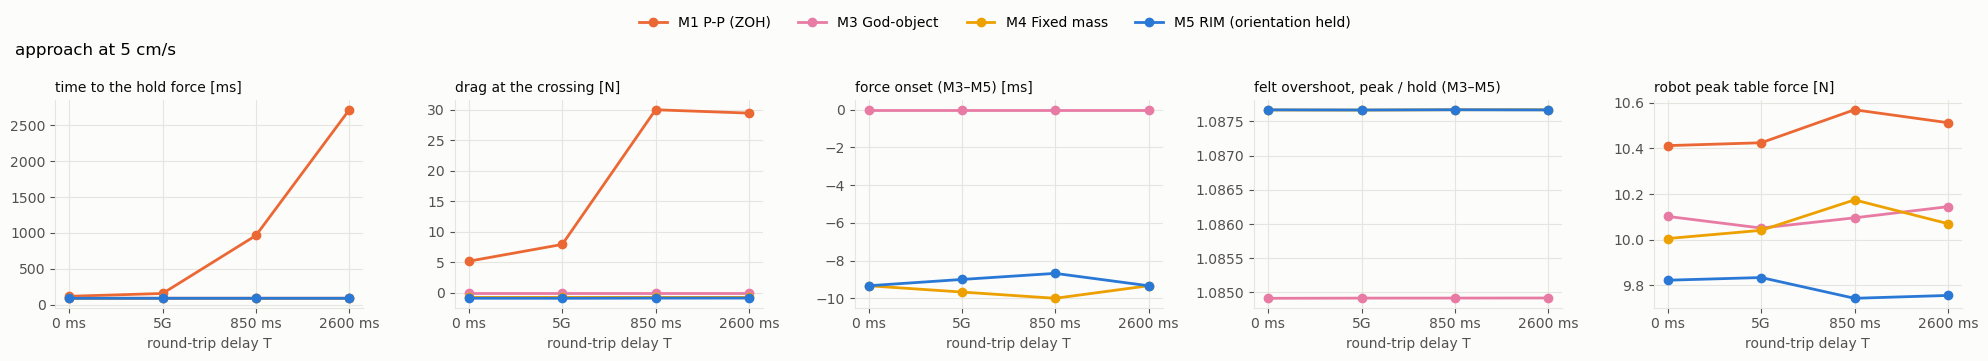

In [6]:
sub = df[np.isclose(df.approach_speed.astype(float), SWEEP_SPEED) & ~df.steady]
fig, axes = plt.subplots(1, len(metrics), figsize=(4 * len(metrics), 3.3))
for ax, (y, title) in zip(axes, metrics):
    s = (
        sub if y not in ("onset_latency_ms_mean", "overshoot_mean") else sub[sub.method != "zoh"]
    )  # M1: drag, not an onset
    P.by_delay(ax, s, y, label_methods=(ax is axes[0]))
    ax.set_title(title, loc="left", fontsize=10)
fig.suptitle(f"approach at {100 * SWEEP_SPEED:g} cm/s", x=0.01, ha="left")
fig.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.1))
fig.tight_layout()

## M3–M5 at a steady approach speed

In the main sweeps the leader reaches its speed 3 cm above the table, and the M4/M5 proxy — a mass on the
coupling, lightly damped (ζ ≈ 0.3, decay ~0.34 s) — is still catching up at contact: at 20 cm/s it is
~14 mm above the leader with ~15 N of inertial drag, and meets the table 50 ms late. The steady sweep (label
`steady`: 20 cm pre-height, ≥ 1 s at constant speed before contact; M4's mass tuned at the contact) lets the
proxies meet the table at the leader's speed. Solid: steady; dashed: the main sweep's 3 cm pre-height.

What to expect: the table is a rigid unilateral constraint, so a proxy arriving at a steady speed has its
velocity projected away — the momentum ($mv$, $\Lambda v$) goes into the table as an impulse and never
reaches the operator. If M3, M4 and M5 coincide here, the M3–M5 differences of the main sweep come from the
accelerations before contact (the inertia E1 and E2 measure), not from momentum at impact.

**Outcome (2026-10-26): they coincide.** Felt peak 10.85 / 10.88 / 10.88 N at 5 cm/s, 13.4 N at 10 cm/s and
19.7–19.9 N at 20 cm/s for M3 / M4 / M5; drag at the crossing and onset ≈ 0 for all (M4 at 20 cm/s: 1.0 N,
+4 ms, residual ringing). The robot's impact converges too: 19.4 / 19.0 / 21.9 N at 20 cm/s, against
34 / 24.7 / 25.4 N with the 3 cm pre-height.

felt_at_crossing_N_mean felt_peak_N_mean  \
steady                                            False            False   
approach_speed method                                                      
0.01           proxy-fixed-mass                   -0.00            10.18   
               proxy-god-object                    0.00            10.17   
               proxy-rim                           0.00            10.18   
0.05           proxy-fixed-mass                   -0.80            10.88   
               proxy-god-object                    0.00            10.85   
               proxy-rim                          -0.91            10.88   
0.10           proxy-fixed-mass                    1.85            13.44   
               proxy-god-object                    0.00            13.36   
               proxy-rim                           2.32            13.44   
0.20           proxy-fixed-mass                   15.95            15.99   
               proxy-god-object                    0.00            19.71   
               proxy-rim                          15.04            16.25   

                                onset_latency_ms_mean robot_peak_table_N_mean  
steady                                          False                   False  
approach_speed method                                                          
0.01           proxy-fixed-mass                 29.00                    9.74  
               proxy-god-object                 30.00                    9.79  
               proxy-rim                        29.00                    9.43  
0.05           proxy-fixed-mass                -10.00                   10.17  
               proxy-god-object                  0.00                   10.10  
               proxy-rim                        -8.68                    9.74  
0.10           proxy-fixed-mass                 15.67                   19.08  
               proxy-god-object                  0.00                   15.88  
               proxy-rim                        19.67                   16.94  
0.20           proxy-fixed-mass                 50.00                   24.73  
               proxy-god-object                  0.00                   34.01  
               proxy-rim                        49.00                   25.37

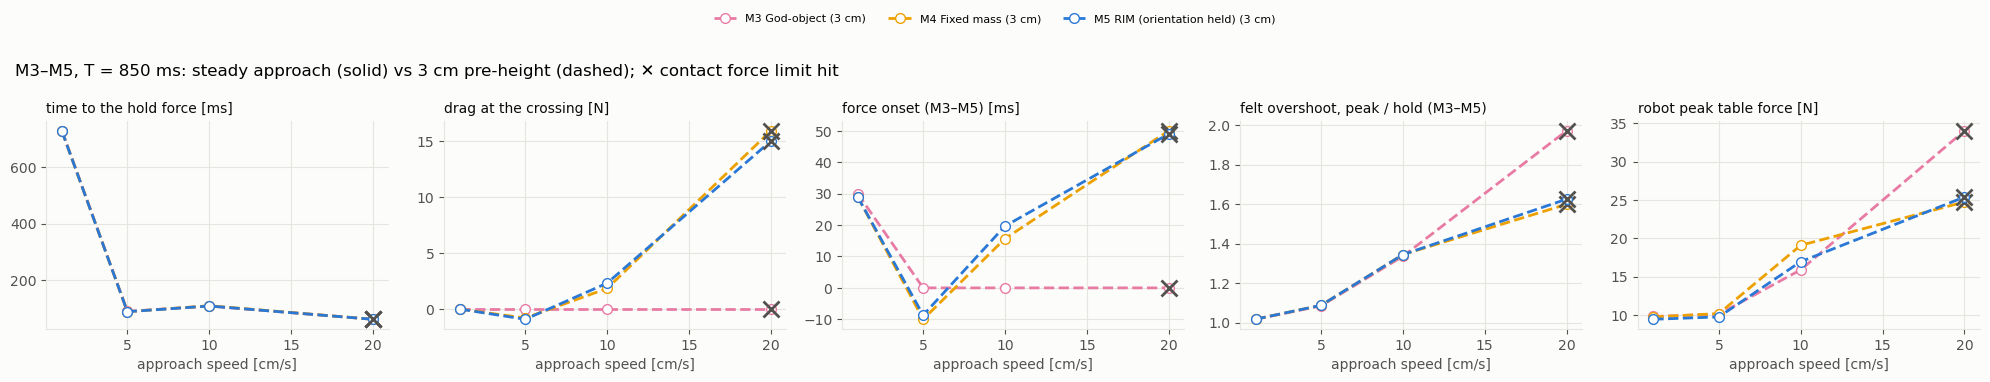

In [7]:
models = ["proxy-god-object", "proxy-fixed-mass", "proxy-rim"]
cmp = df[df.method.isin(models) & (df["T"] == SWEEP_RTT)]
fig, axes = plt.subplots(1, len(metrics), figsize=(4 * len(metrics), 3.3))
for ax, (y, title) in zip(axes, metrics):
    for m in [m for m in P.methods_in(cmp) if m in models]:
        for st, ls in ((True, "-"), (False, "--")):
            s = (
                cmp[(cmp.method == m) & (cmp.steady == st)]
                .groupby("approach_speed")[[y, "contact_limited_mean"]]
                .mean()
            )
            if s.empty:
                continue
            ax.plot(
                100 * s.index,
                s[y],
                "o" + ls,
                lw=2,
                ms=7,
                color=P.color(m),
                mfc=P.color(m) if st else "white",
                label=f"{P.LABELS.get(m, m)}{' (steady)' if st else ' (3 cm)'}" if ax is axes[0] else None,
            )
            lim = s.contact_limited_mean > 0
            ax.plot(100 * s.index[lim], s[y][lim], "x", ms=11, mew=2, color=P.INK_2)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("approach speed [cm/s]")
fig.suptitle(
    f"M3–M5, T = {SWEEP_RTT} ms: steady approach (solid) vs 3 cm pre-height (dashed); ✕ contact force limit hit",
    x=0.01,
    ha="left",
)
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.16), fontsize=8)
fig.tight_layout()
cmp.pivot_table(
    index=["approach_speed", "method"],
    columns="steady",
    values=["felt_peak_N_mean", "felt_at_crossing_N_mean", "onset_latency_ms_mean", "robot_peak_table_N_mean"],
).round(2)

## Time series of single contacts

For each condition in `TIMESERIES`, approach `CONTACT` of every method. Top: heights above the table — leader
(solid), proxy (dotted, M3–M5), robot (dashed, grey). Bottom: the felt force (solid) and the robot's table force
$-F_{osc,z}$ (dashed, grey), each on its own side's clock, so under delay the felt contact comes a feedback delay
after the robot's. Marked: the crossing (t = 0), the force onset (dot, when defined), the time to the hold force
(dashed, method colour) and the hold force (dotted); the box lists the contact's metrics.

T = 850, 20 cm/s, steady: no runs


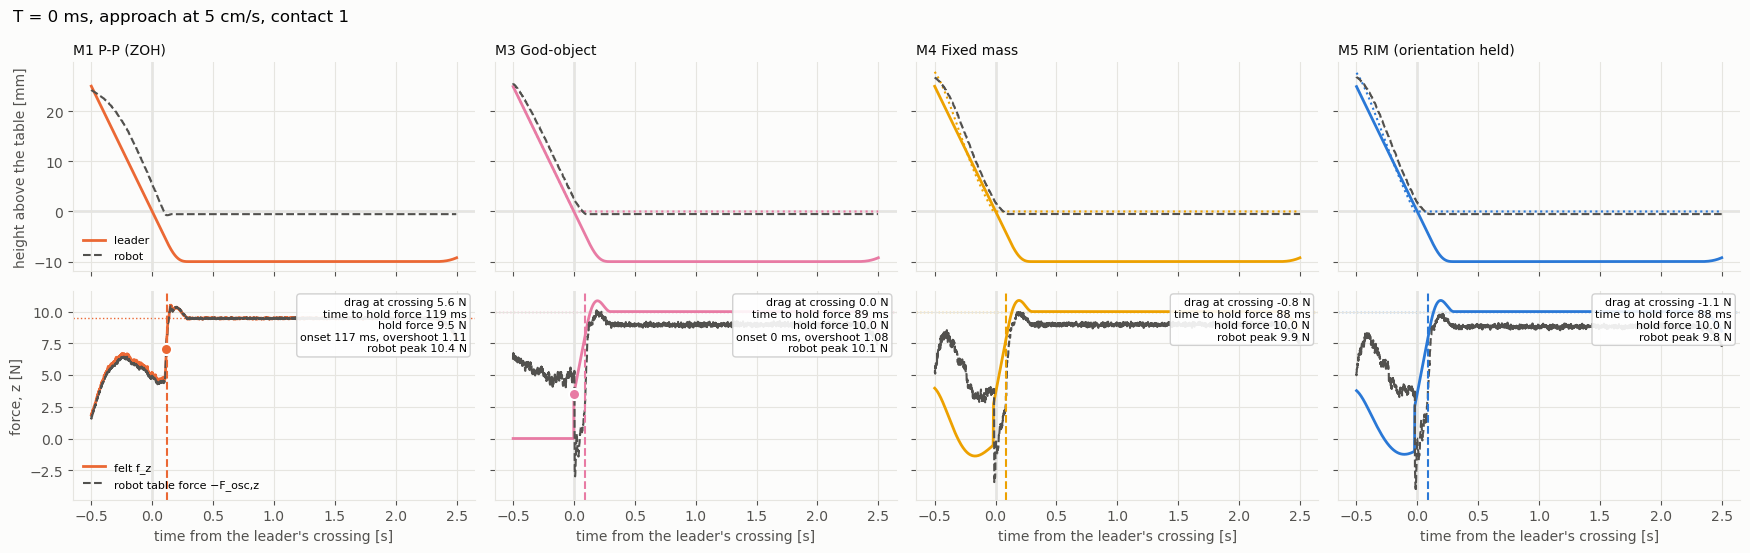

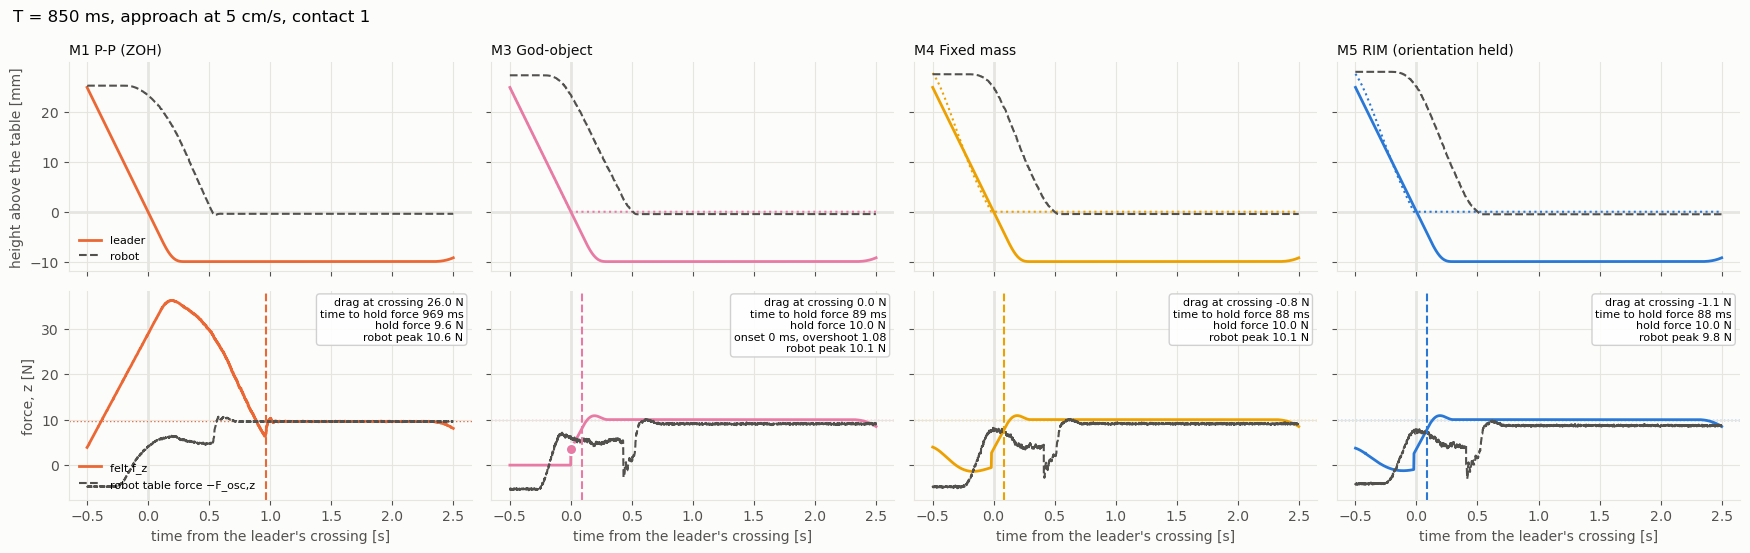

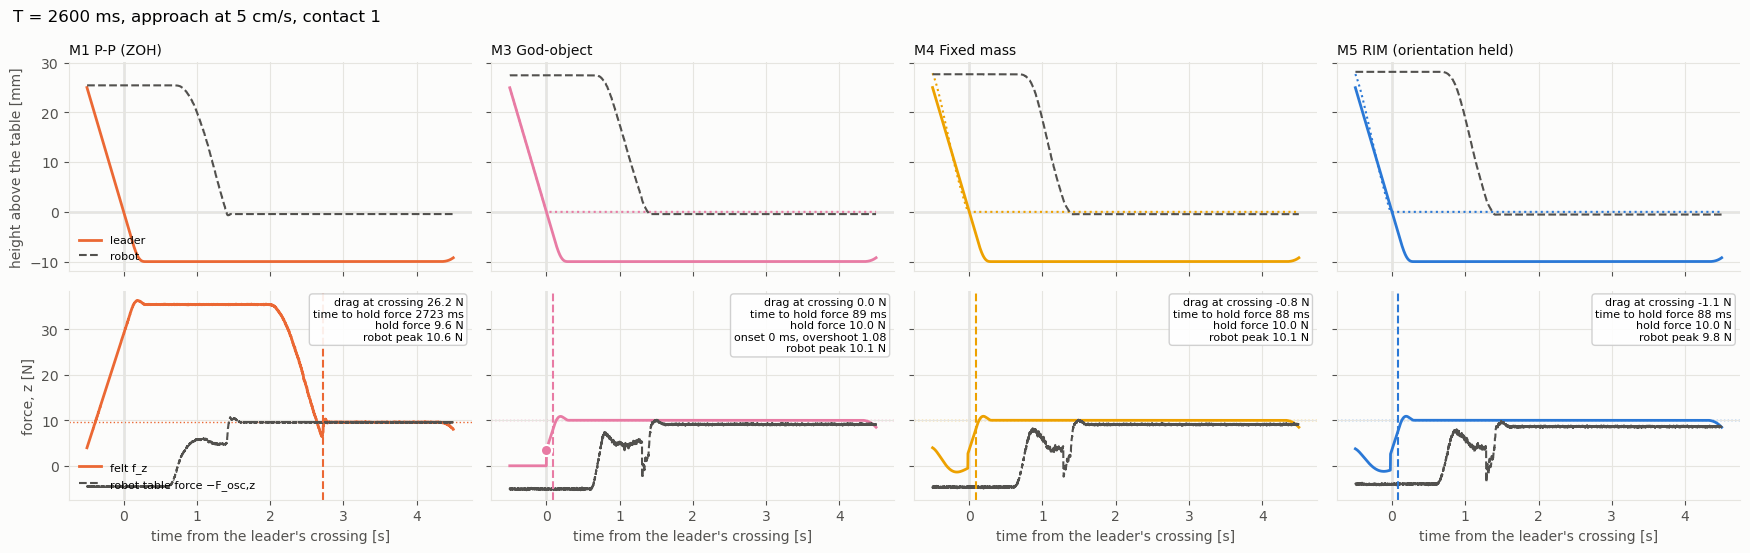

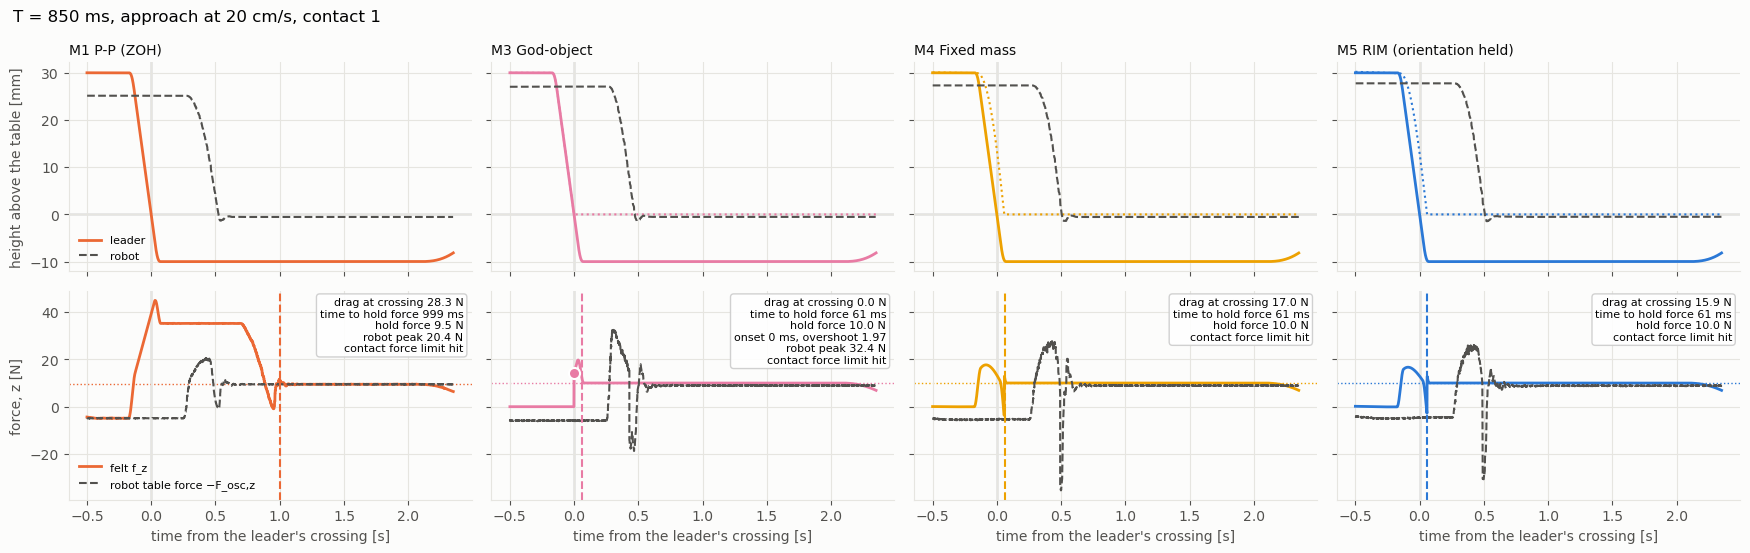

In [8]:
for T, v, steady in TIMESERIES:
    pick = df[(df["T"] == T) & np.isclose(df.approach_speed.astype(float), v) & (df.steady == steady)]
    methods = P.methods_in(pick)
    if not methods:
        print(f"T = {T}, {100 * v:g} cm/s{', steady' if steady else ''}: no runs")
        continue
    fig, axes = plt.subplots(
        2, len(methods), figsize=(4.4 * len(methods), 5.6), sharex=True, sharey="row", squeeze=False
    )
    for j, m in enumerate(methods):
        row = pick[pick.method == m].iloc[0]
        run = loaded[row.dir]
        res = exp_metrics.e3(run)
        contact = res["per_contact"][min(CONTACT, len(res["per_contact"]) - 1)]
        at_depth = run["meta"]["script"]["depth"] / v + run["meta"]["script"]["hold_s"]
        P.contact_panel(axes[0, j], axes[1, j], run, contact, m, window_s=at_depth)
        axes[0, j].set_title(P.LABELS.get(m, m), loc="left", fontsize=10)
        axes[1, j].set_xlabel("time from the leader's crossing [s]")
    axes[0, 0].set_ylabel("height above the table [mm]")
    axes[1, 0].set_ylabel("force, z [N]")
    axes[0, 0].legend(fontsize=8, frameon=False, loc="lower left")
    axes[1, 0].legend(fontsize=8, frameon=False, loc="lower left")
    fig.suptitle(
        f"T = {T if T == '5g' else T + ' ms'}, approach at {100 * v:g} cm/s"
        f"{' (steady, 20 cm pre-height)' if steady else ''}, contact {CONTACT}",
        x=0.01,
        ha="left",
    )
    fig.tight_layout()

## Discussion (2026-10-26, 37 runs)

**Model-based vs P-P (the E3 message).**
- **The contact arrives a round trip late with M1, at once with M3–M5.** Time to the hold force at 5 cm/s:
  M1 116 / 155 / 965 / 2719 ms at T = 0 / 5G / 850 ms / 2.6 s (≈ T plus the robot's ~100 ms tracking lag and
  settling, < 10 ms spread over a run's three contacts); M3–M5 88–89 ms at every delay.
- **M1 drags before contact.** Felt force at the crossing ~5 N at T = 0, ~30 N at 850 ms and 2.6 s; it stops
  growing with the speed above ~10 cm/s because the leader starts from rest 3 cm above the table (at most
  K × 3 cm). M3–M5 feel nothing before contact at a constant approach speed.
- **Unfelt force in contact (e_F,z):** M1 0 / 0 / 7.8 / 16.3 N at T = 0 / 5G / 850 / 2600; M3–M5 1.0–1.5 N at
  every delay (the robot's +1.3 N z bias and friction).
- **The hold force is K × depth for M3–M5** (10.0 N) and 9.5 N for M1 (through the real OSC), once the contact
  has arrived. At low speed (1 cm/s) M3–M5 coincide; M1 still drags and arrives late — the delay is still there.

**Which model (M3 vs M4 vs M5).**
- **At a steady approach speed they coincide**, felt and robot side: the table is a rigid unilateral constraint,
  so the proxy's momentum ($mv$, $\Lambda v$) goes into the table as an impulse and never reaches the operator.
  The plan's expected momentum transients (Λv for M5, mv for M4, none for M3) do not appear at contact.
- **They differ when the leader accelerates just before contact** (the main sweep: full speed in 50 ms, 3 cm
  above the table at 20 cm/s): the M4/M5 proxy — a mass on the coupling (ζ ≈ 0.3) — lags the leader by ~14 mm,
  the operator feels ~15 N of the arm's inertia as drag, and the contact comes 50 ms later with the leader 9 mm
  deep; M3's massless proxy stops dead at the surface. This is the inertia E1 and E2 measure, not momentum at
  impact. M4 ≈ M5 throughout: M4's mass is Λ_zz near the contact configuration.
- **Robot impact:** with the 3 cm pre-height M3's robot hit hardest (34 N at 20 cm/s: the robot's own transient
  behind a leader that started abruptly, plus M3's feedforward of the coupling damping D·v); steady, all three
  hit at 19–22 N.

**Caveats.**
- **Contact force limiter.** At 20 cm/s osc_controller's limiter (50 N on libfranka's external-force estimate)
  fires at nearly every impact, every method (short spikes of a stiff tool hitting the table at ~18–20 cm/s):
  flagged ✕; those contacts' robot peak force is shaped by the cap.
- **Scripted leader.** The coupling rings after the leader's start ramp (M4/M5 proxy ~1 mm ahead and −1 N at
  5 cm/s in the main sweep, hence onsets of −9 ms); a hand on the device would damp it.
- **M1's onset and overshoot are not defined under delay** (it drags more before contact than it feels in it):
  read its time to the hold force.